In [1]:
## Learning Outcomes

#* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
#* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
#* Practice how the environment and the agent function interact.
#* Analyze agent performance through controlled experiments across different environment configurations.

In [2]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Mounted at /content/drive
Your working directory is now Google Drive: My Drive > Colab Notebooks


In [3]:
## Introduction & PEAS Description

### PEAS Description of the Cleaning Phase
#* **Performance Measure:** Mỗi hành động tốn 1 đơn vị năng lượng. Hiệu năng được đo bằng tổng số bước (năng lượng) tiêu thụ cho đến khi toàn bộ phòng được làm sạch.
#* **Environment:** Phòng lưới $n \times n$. Rác được phân bố ngẫu nhiên với xác suất $p = 0.2$. Robot bắt đầu tại vị trí ngẫu nhiên.
#* **Actuators:** `suck` (hút bụi), `north`, `east`, `south`, `west` (di chuyển).
#* **Sensors:** 4 cảm biến va chạm `bumpers` (`north`, `east`, `south`, `west`) và cảm biến độ bẩn `dirty`.

In [4]:
# Google Colab package check
# %pip install -q "numpy>=1.26,<3" pandas matplotlib

In [5]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [6]:
# Ví dụ percepts (vị trí ở góc Tây-Bắc và bẩn)
bumpers = {"north": True, "east": False, "south": False, "west": True}
dirty = True

# Gọi tác tử
simple_randomized_agent(bumpers, dirty)

np.str_('east')

In [7]:
def simple_environment(agent_function, max_steps, verbose=True):
    num_cleaned = 0
    for i in range(max_steps):
        dirty = True
        bumpers = {"north": False, "south": False, "west": False, "east": False}

        action = agent_function(bumpers, dirty)
        if verbose:
            print("step", i, "- action:", action)

        if action == "suck":
            num_cleaned += 1

    return num_cleaned

In [8]:
simple_environment(simple_randomized_agent, max_steps=20)

step 0 - action: suck
step 1 - action: south
step 2 - action: east
step 3 - action: suck
step 4 - action: north
step 5 - action: east
step 6 - action: north
step 7 - action: east
step 8 - action: east
step 9 - action: north
step 10 - action: east
step 11 - action: west
step 12 - action: east
step 13 - action: west
step 14 - action: west
step 15 - action: south
step 16 - action: south
step 17 - action: east
step 18 - action: suck
step 19 - action: east


3

In [9]:
# Tasks

## Task 1: Implement a simulation environment [20 Points]

#Môi trường mô phỏng `run_environment` tuân thủ đầy đủ mô tả PEAS:
#- Khởi tạo mảng 2D kích thước $n \times n$ lưu trạng thái ô sạch (0) hoặc bẩn (1) với xác suất $p=0.2$.
#- Theo dõi vị trí tọa độ của tác tử `[row, col]`.
#- Cung cấp dữ liệu cảm biến chính xác (`bumpers` chứa 4 hướng tường và `dirty` báo trạng thái ô hiện tại).
#- Phản ứng với các hành động: hút sạch ô khi chọn `suck` hoặc di chuyển vị trí nếu không va tường.
#- Đo lường tổng số bước năng lượng sử dụng cho tới khi toàn bộ phòng sạch hoàn toàn.

In [10]:
import numpy as np
import random

def run_environment(agent_function, n=5, p=0.2, max_steps=1000, verbose=False):
    """
    Môi trường mô phỏng phòng n x n chuẩn hóa theo mô tả PEAS.
    """
    # Khởi tạo phòng: 1 là bẩn, 0 là sạch
    grid = (np.random.rand(n, n) < p).astype(int)

    # Vị trí xuất phát ngẫu nhiên của robot
    pos = [np.random.randint(0, n), np.random.randint(0, n)]

    # Nếu tác tử có trạng thái bộ nhớ nội bộ, gọi hàm reset()
    if hasattr(agent_function, "reset"):
        agent_function.reset()

    steps = 0

    while steps < max_steps:
        # Điều kiện dừng: Toàn bộ phòng đã sạch
        if np.sum(grid) == 0:
            break

        r, c = pos
        # Tạo thông tin cảm biến truyền cho tác tử
        bumpers = {
            "north": r == 0,
            "east": c == n - 1,
            "south": r == n - 1,
            "west": c == 0
        }
        dirty = bool(grid[r, c] == 1)

        # Nhận hành động từ tác tử
        action = agent_function(bumpers, dirty)
        steps += 1

        if verbose:
            print(f"Bước {steps:02d} | Vị trí: ({r}, {c}) | Bẩn: {dirty} | Bumpers: {bumpers} -> Hành động: {action}")

        # Thực thi hành động
        if action == "suck":
            grid[r, c] = 0
        elif action == "north" and not bumpers["north"]:
            pos[0] -= 1
        elif action == "south" and not bumpers["south"]:
            pos[0] += 1
        elif action == "west" and not bumpers["west"]:
            pos[1] -= 1
        elif action == "east" and not bumpers["east"]:
            pos[1] += 1

    return steps

In [11]:
#Kiểm tra môi trường mô phỏng thực tế vừa xây dựng với **Simple Randomized Agent** (ngân sách 20 bước).

In [12]:
print("=== THỬ NGHIỆM TASK 1: RUN ENVIRONMENT VỚI RANDOMIZED AGENT (MAX 20 BƯỚC) ===")
steps_used = run_environment(simple_randomized_agent, n=5, p=0.2, max_steps=20, verbose=True)
print(f"\nTổng số bước năng lượng đã tiêu thụ: {steps_used}")

=== THỬ NGHIỆM TASK 1: RUN ENVIRONMENT VỚI RANDOMIZED AGENT (MAX 20 BƯỚC) ===
Bước 01 | Vị trí: (3, 4) | Bẩn: False | Bumpers: {'north': False, 'east': True, 'south': False, 'west': False} -> Hành động: suck
Bước 02 | Vị trí: (3, 4) | Bẩn: False | Bumpers: {'north': False, 'east': True, 'south': False, 'west': False} -> Hành động: south
Bước 03 | Vị trí: (4, 4) | Bẩn: False | Bumpers: {'north': False, 'east': True, 'south': True, 'west': False} -> Hành động: west
Bước 04 | Vị trí: (4, 3) | Bẩn: True | Bumpers: {'north': False, 'east': False, 'south': True, 'west': False} -> Hành động: west
Bước 05 | Vị trí: (4, 2) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': True, 'west': False} -> Hành động: south
Bước 06 | Vị trí: (4, 2) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': True, 'west': False} -> Hành động: west
Bước 07 | Vị trí: (4, 1) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': True, 'west': False} -> Hành động: west
Bước 08 | Vị

In [13]:
## Task 2: Implement a simple reflex agent [10 Points]

#Tác tử phản xạ đơn giản (`simple_reflex_agent`):
#- Nếu cảm biến báo ô bẩn (`dirty == True`) $\rightarrow$ Thực hiện hút bụi (`suck`).
#- Ngược lại (`dirty == False`) $\rightarrow$ Lọc danh sách các hướng không đụng tường (`bumpers == False`) và chọn ngẫu nhiên một hướng di chuyển hợp lệ.

In [14]:
def simple_reflex_agent(bumpers, dirty):
    """
    Tác tử phản xạ đơn giản biết phản ứng với cảm biến tường và độ bẩn.
    """
    if dirty:
        return "suck"

    # Lọc ra danh sách các hướng di chuyển không đụng tường
    valid_moves = [direction for direction, is_bumped in bumpers.items() if not is_bumped]

    if valid_moves:
        return random.choice(valid_moves)

    return "suck"

In [15]:
#Kiểm tra hoạt động của **Simple Reflex Agent** trong môi trường phòng $5 \times 5$.

In [16]:
print("=== THỬ NGHIỆM TASK 2: SIMPLE REFLEX AGENT ===")
steps_used = run_environment(simple_reflex_agent, n=5, p=0.2, max_steps=100, verbose=True)
print(f"\nTổng số bước tiêu thụ để làm sạch phòng 5x5: {steps_used}")

=== THỬ NGHIỆM TASK 2: SIMPLE REFLEX AGENT ===
Bước 01 | Vị trí: (4, 2) | Bẩn: True | Bumpers: {'north': False, 'east': False, 'south': True, 'west': False} -> Hành động: suck
Bước 02 | Vị trí: (4, 2) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': True, 'west': False} -> Hành động: north
Bước 03 | Vị trí: (3, 2) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': False, 'west': False} -> Hành động: west
Bước 04 | Vị trí: (3, 1) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': False, 'west': False} -> Hành động: east
Bước 05 | Vị trí: (3, 2) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': False, 'west': False} -> Hành động: west
Bước 06 | Vị trí: (3, 1) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': False, 'west': False} -> Hành động: north
Bước 07 | Vị trí: (2, 1) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': False, 'west': False} -> Hành động: south
Bước 08 | Vị trí: (3, 1) | Bẩn: Fals

In [17]:
## Task 3: Implement a model-based reflex agent [20 Points]

### Chiến lược & Trạng thái Bên trong (Internal State):
#1. **Trạng thái nội bộ (`mode` & `sweep_direction`):**
 #  - `mode`: Lần lượt chuyển qua 3 giai đoạn: `"GOTO_NW"` (tìm về góc Tây-Bắc), `"SWEEP"` (quét hệ thống zích-zắc), và `"DONE"` (hoàn thành).
  # - `sweep_direction`: Hướng di chuyển quét ngang hiện tại (`"east"` hoặc `"west"`).

#2. **Quy trình hoạt động:**
 #  - **Làm sạch:** Bất kỳ lúc nào `dirty == True`, ưu tiên thực hiện `"suck"`.
  # - **Định vị (`GOTO_NW`):** Do robot chưa biết tọa độ xuất phát, nó đi lên phía Bắc cho đến khi gặp tường (`north=True`), rồi đi sang Tây đến khi gặp tường (`west=True`). Lúc này đảm bảo robot ở góc Tây-Bắc $(0, 0)$.
   #- **Quét đường zích zắc (`SWEEP` - Boustrophedon Sweep):** Đi hết hàng sang Đông, hạ xuống 1 ô phía Nam, rồi quét ngược sang Tây. Chu trình lặp lại đến khi chạm tường phía Nam (`south=True`). Chiến lược này đảm bảo đi qua $100\%$ diện tích phòng một cách tối ưu nhất.

In [18]:
class ModelBasedReflexAgent:
    """
    Tác tử phản xạ dựa trên mô hình có lưu trạng thái bên trong.
    """
    def __init__(self):
        self.reset()

    def reset(self):
        self.mode = "GOTO_NW"
        self.sweep_direction = "east"

    def __call__(self, bumpers, dirty):
        # 1. Nếu ô bẩn -> Thực hiện Hút bụi
        if dirty:
            return "suck"

        # 2. Giai đoạn định vị: Di chuyển về góc Tây-Bắc (0,0)
        if self.mode == "GOTO_NW":
            if not bumpers["north"]:
                return "north"
            elif not bumpers["west"]:
                return "west"
            else:
                self.mode = "SWEEP"
                self.sweep_direction = "east"

        # 3. Giai đoạn quét hệ thống zích zắc (Boustrophedon Sweep)
        if self.mode == "SWEEP":
            if self.sweep_direction == "east":
                if not bumpers["east"]:
                    return "east"
                elif not bumpers["south"]:
                    self.sweep_direction = "west"
                    return "south"
                else:
                    self.mode = "DONE"
                    return "suck"
            elif self.sweep_direction == "west":
                if not bumpers["west"]:
                    return "west"
                elif not bumpers["south"]:
                    self.sweep_direction = "east"
                    return "south"
                else:
                    self.mode = "DONE"
                    return "suck"

        return "suck"

In [19]:
#Kiểm tra hoạt động của **Model-Based Reflex Agent** trong môi trường phòng $5 \times 5$.

In [20]:
model_agent = ModelBasedReflexAgent()
print("=== THỬ NGHIỆM TASK 3: MODEL-BASED REFLEX AGENT ===")
steps_used = run_environment(model_agent, n=5, p=0.2, max_steps=100, verbose=True)
print(f"\nTổng số bước tiêu thụ để làm sạch hoàn toàn phòng 5x5: {steps_used}")

=== THỬ NGHIỆM TASK 3: MODEL-BASED REFLEX AGENT ===
Bước 01 | Vị trí: (3, 3) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': False, 'west': False} -> Hành động: north
Bước 02 | Vị trí: (2, 3) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': False, 'west': False} -> Hành động: north
Bước 03 | Vị trí: (1, 3) | Bẩn: False | Bumpers: {'north': False, 'east': False, 'south': False, 'west': False} -> Hành động: north
Bước 04 | Vị trí: (0, 3) | Bẩn: False | Bumpers: {'north': True, 'east': False, 'south': False, 'west': False} -> Hành động: west
Bước 05 | Vị trí: (0, 2) | Bẩn: True | Bumpers: {'north': True, 'east': False, 'south': False, 'west': False} -> Hành động: suck
Bước 06 | Vị trí: (0, 2) | Bẩn: False | Bumpers: {'north': True, 'east': False, 'south': False, 'west': False} -> Hành động: west
Bước 07 | Vị trí: (0, 1) | Bẩn: False | Bumpers: {'north': True, 'east': False, 'south': False, 'west': False} -> Hành động: west
Bước 08 | Vị trí: (0, 0) | Bẩn: T

In [21]:
## Task 4: Simulation study [30 Points]

#Tiến hành mô phỏng so sánh năng lượng tiêu thụ (số bước trung bình) của 3 tác tử trên 3 kích thước phòng: $5 \times 5$, $10 \times 10$, và $100 \times 100$. Mỗi cấu hình chạy **100 lần ngẫu nhiên**.

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

sizes = [5, 10, 100]
num_runs = 100

# Ngưỡng max_steps an toàn cho từng kích thước phòng
max_steps_dict = {
    5: 3000,
    10: 15000,
    100: 50000
}

model_agent = ModelBasedReflexAgent()
summary_data = []

print("Đang chạy mô phỏng 100 lần cho từng cấu hình...")

for n in sizes:
    max_s = max_steps_dict[n]

    # 1. Simple Randomized Agent
    rand_scores = []
    for _ in range(num_runs):
        steps = run_environment(simple_randomized_agent, n=n, p=0.2, max_steps=max_s, verbose=False)
        rand_scores.append(steps)

    # 2. Simple Reflex Agent
    reflex_scores = []
    for _ in range(num_runs):
        steps = run_environment(simple_reflex_agent, n=n, p=0.2, max_steps=max_s, verbose=False)
        reflex_scores.append(steps)

    # 3. Model-Based Reflex Agent
    model_scores = []
    for _ in range(num_runs):
        steps = run_environment(model_agent, n=n, p=0.2, max_steps=max_s, verbose=False)
        model_scores.append(steps)

    summary_data.append({
        "Size": f"{n}x{n}",
        "Randomized Agent": round(np.mean(rand_scores), 2),
        "Simple Reflex Agent": round(np.mean(reflex_scores), 2),
        "Model-based Reflex Agent": round(np.mean(model_scores), 2)
    })

# Tạo Bảng Kết Quả
df_results = pd.DataFrame(summary_data)
print("\n=== BẢNG KẾT QUẢ SO SÁNH NĂNG LƯỢNG TRUNG BÌNH (100 LẦN CHẠY) ===")
display(df_results)

Đang chạy mô phỏng 100 lần cho từng cấu hình...

=== BẢNG KẾT QUẢ SO SÁNH NĂNG LƯỢNG TRUNG BÌNH (100 LẦN CHẠY) ===


,Size,Randomized Agent,Simple Reflex Agent,Model-based Reflex Agent
0,5x5,432.45,87.64,28.01
1,10x10,3204.16,892.68,123.87
2,100x100,50000.00,50000.00,12096.60


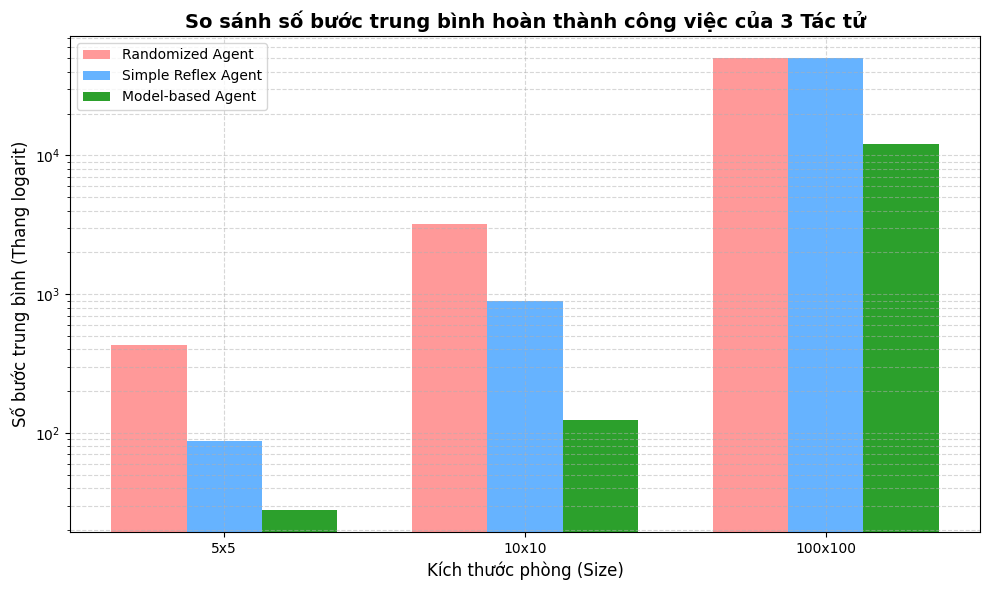

In [23]:
# Vẽ biểu đồ cột so sánh kết quả
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(sizes))
width = 0.25

rects1 = ax.bar(x - width, df_results["Randomized Agent"], width, label="Randomized Agent", color="#ff9999")
rects2 = ax.bar(x, df_results["Simple Reflex Agent"], width, label="Simple Reflex Agent", color="#66b3ff")
rects3 = ax.bar(x + width, df_results["Model-based Reflex Agent"], width, label="Model-based Agent", color="#2ca02c")

ax.set_xlabel("Kích thước phòng (Size)", fontsize=12)
ax.set_ylabel("Số bước trung bình (Thang logarit)", fontsize=12)
ax.set_title("So sánh số bước trung bình hoàn thành công việc của 3 Tác tử", fontsize=14, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(df_results["Size"])
ax.set_yscale("log") # Thang đo logarit do sự chênh lệch bước quá lớn
ax.legend()
ax.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [24]:
### Nhận xét & Thảo luận kết quả Task 4:
#1. **Randomized Agent:** Hiệu năng rất kém. Do đi hoàn toàn ngẫu nhiên và dễ đâm tường liên tục, số bước tiêu thụ tăng bùng nổ theo kích thước phòng.
#2. **Simple Reflex Agent:** Tốt hơn tác tử ngẫu nhiên do biết tránh tường và biết hút khi gặp bẩn. Tuy nhiên, vì di chuyển chọn hướng ngẫu nhiên, tác tử dễ bị quẩn quanh một khu vực và tốn rất nhiều năng lượng để phủ hết toàn bộ phòng.
#3. **Model-based Reflex Agent:** Cho hiệu năng tối ưu nhất. Nhờ chiến lược quét zích-zắc (Boustrophedon sweep), tác tử đi qua mỗi ô đúng số lần cần thiết và hoàn thành công việc với số bước gần như tối thiểu ($O(N^2)$).

In [25]:
## Task 5: Robustness of the agent implementations [10 Points]

### Phân tích độ bền vững của các cài đặt tác tử:

#1. **Phòng chữ nhật kích thước chưa biết ($n \times m$):**
 #  - **Randomized & Simple Reflex Agent:** Hoạt động dựa trên xác suất nhưng vô cùng lãng phí năng lượng.
  # - **Model-based Agent:** Cài đặt dựa vào cảm biến va chạm tường (`bumpers`) để chuyển hướng và chuyển dòng. Do đó tác tử **vẫn hoạt động hoàn hảo** trên phòng chữ nhật bất kỳ mà không cần biết trước $n$ hay $m$.

#2. **Phòng có hình dạng bất thường (hành lang nối 2 phòng):**
 #  - **Randomized & Simple Reflex Agent:** Có thể lọt qua hành lang hẹp nhờ di chuyển ngẫu nhiên.
  # - **Model-based Agent:** Thuật toán quét thẳng dòng sẽ bị dừng sớm khi va vào tường lồi của hành lang, dẫn đến **bỏ sót các vùng phía sau**. Cần nâng cấp lên thuật toán tìm kiếm theo chiều sâu/rộng (DFS/BFS) với bản đồ bộ nhớ.

#3. **Phòng có vật cản bên trong (Obstacles):**
 #  - **Simple Reflex Agent:** Tránh vật cản như tránh tường nhưng dễ bị kẹt trong vòng lặp cục bộ.
  # - **Model-based Agent:** Vật cản kích hoạt `bumper` khiến tác tử hiểu nhầm là tường biên phòng và đổi dòng sớm, gây bỏ sót ô.

#4. **Cảm biến độ bẩn nhiễu 10% (Dirty Sensor Error):**
 #  - **Simple Reflex & Randomized Agent:** Thỉnh thoảng bỏ sót ô bẩn hoặc hút nhầm ô sạch.
  # - **Model-based Agent:** Vì quét qua mỗi ô đúng 1 lần, nếu cảm biến báo nhầm "sạch" khi ô bẩn, tác tử sẽ bỏ qua và **không bao giờ quay lại**, khiến phòng không được làm sạch $100\%$.

#5. **Cảm biến va chạm nhiễu 10% (Không báo tường):**
 #  - Tác tử cố di chuyển vào tường, hành động thất bại (tốn 1 bước năng lượng). Với Model-based agent, điều này gây mất đồng bộ chu trình quét.

In [26]:
## Advanced task: Imperfect Dirt Sensor [10 Points]

#1. **Thực nghiệm Cảm biến Nhiễu 10%:** Môi trường `run_imperfect_environment` có $10\%$ xác suất trả về kết quả `dirty` sai.
#2. **Giải pháp Cải tiến (`RobustModelBasedAgent`):** Áp dụng chiến lược **Quét 2 lượt (Multi-pass Sweep)**. Việc quét lại giúp giảm xác suất một ô bẩn bị bỏ sót từ $10\%$ xuống còn $0.10 \times 0.10 = 1\%$, nâng cao độ sạch của phòng một cách rõ rệt.

In [27]:
def run_imperfect_environment(agent_function, n=5, p=0.2, noise_prob=0.10, max_steps=1000, verbose=False):
    """
    Môi trường mô phỏng với cảm biến độ bẩn bị nhiễu (noise_prob = 10%).
    """
    grid = (np.random.rand(n, n) < p).astype(int)
    pos = [np.random.randint(0, n), np.random.randint(0, n)]

    if hasattr(agent_function, "reset"):
        agent_function.reset()

    steps = 0

    while steps < max_steps:
        if np.sum(grid) == 0:
            break

        r, c = pos
        bumpers = {
            "north": r == 0,
            "east": c == n - 1,
            "south": r == n - 1,
            "west": c == 0
        }

        # Nhiễu cảm biến 10%
        real_dirty = bool(grid[r, c] == 1)
        noisy_dirty = not real_dirty if random.random() < noise_prob else real_dirty

        action = agent_function(bumpers, noisy_dirty)
        steps += 1

        if action == "suck":
            grid[r, c] = 0
        elif action == "north" and not bumpers["north"]:
            pos[0] -= 1
        elif action == "south" and not bumpers["south"]:
            pos[0] += 1
        elif action == "west" and not bumpers["west"]:
            pos[1] -= 1
        elif action == "east" and not bumpers["east"]:
            pos[1] += 1

    uncleaned_squares = np.sum(grid)
    return steps, uncleaned_squares


class RobustModelBasedAgent:
    """
    Tác tử Mô hình Cải tiến chống Nhiễu (Quét 2 lượt).
    """
    def __init__(self):
        self.reset()

    def reset(self):
        self.mode = "GOTO_NW"
        self.sweep_direction = "east"
        self.pass_count = 1

    def __call__(self, bumpers, dirty):
        if dirty:
            return "suck"

        if self.mode == "GOTO_NW":
            if not bumpers["north"]:
                return "north"
            elif not bumpers["west"]:
                return "west"
            else:
                self.mode = "SWEEP"
                self.sweep_direction = "east"

        if self.mode == "SWEEP":
            if self.sweep_direction == "east":
                if not bumpers["east"]:
                    return "east"
                elif not bumpers["south"]:
                    self.sweep_direction = "west"
                    return "south"
                else:
                    if self.pass_count < 2:
                        self.pass_count += 1
                        self.mode = "GOTO_NW"
                    else:
                        self.mode = "DONE"
                    return "suck"
            elif self.sweep_direction == "west":
                if not bumpers["west"]:
                    return "west"
                elif not bumpers["south"]:
                    self.sweep_direction = "east"
                    return "south"
                else:
                    if self.pass_count < 2:
                        self.pass_count += 1
                        self.mode = "GOTO_NW"
                    else:
                        self.mode = "DONE"
                    return "suck"

        return "suck"

# Chạy thực nghiệm so sánh
num_tests = 100
n_test = 10

std_agent = ModelBasedReflexAgent()
robust_agent = RobustModelBasedAgent()

std_uncleaned = []
robust_uncleaned = []

for _ in range(num_tests):
    _, u1 = run_imperfect_environment(std_agent, n=n_test, p=0.2, noise_prob=0.10, max_steps=500)
    std_uncleaned.append(u1)

    _, u2 = run_imperfect_environment(robust_agent, n=n_test, p=0.2, noise_prob=0.10, max_steps=1000)
    robust_uncleaned.append(u2)

print(f"=== KẾT QUẢ THỬ NGHIỆM VỚI CẢM BIẾN NHIỄU 10% (PHÒNG {n_test}x{n_test}) ===")
print(f"Số ô bẩn còn sót trung bình - Model Agent Chuẩn (1 lượt): {np.mean(std_uncleaned):.2f} ô")
print(f"Số ô bẩn còn sót trung bình - Robust Model Agent (2 lượt): {np.mean(robust_uncleaned):.2f} ô")

=== KẾT QUẢ THỬ NGHIỆM VỚI CẢM BIẾN NHIỄU 10% (PHÒNG 10x10) ===
Số ô bẩn còn sót trung bình - Model Agent Chuẩn (1 lượt): 1.79 ô
Số ô bẩn còn sót trung bình - Robust Model Agent (2 lượt): 0.12 ô


In [28]:
## Báo cáo ngắn & Kết luận

#1. **Tổng kết kết quả:**
 #  - **Simple Randomized Agent:** Di chuyển không có mục đích, tiêu tốn năng lượng cực lớn và không thể làm sạch hoàn toàn khi không gian mở rộng.
  # - **Simple Reflex Agent:** Biết phản ứng với cảm biến va chạm và độ bẩn, cải thiện đáng kể so với ngẫu nhiên nhưng vẫn tốn nhiều bước do chưa có khả năng nhớ đường.
  # - **Model-Based Reflex Agent:** Đạt hiệu năng tối ưu vượt trội nhờ bộ nhớ trạng thái nội bộ để định vị và di chuyển theo đường zích zắc có hệ thống.

#2. **Bài học rút ra:**
 #  - Việc trang bị trạng thái nội bộ (Model) giúp tác tử chuyển từ phản xạ thụ động sang hoạt động thông minh có kế hoạch, giảm chi phí năng lượng từ mức ngẫu nhiên bùng nổ xuống quy luật tuyến tính $O(N^2)$.
  # - Đối với môi trường thực tế có nhiễu cảm biến, phương pháp quét lại (Multi-pass) giúp đảm bảo sự cân bằng giữa chi phí năng lượng và độ tin cậy.